# Lab 2 — Language-specific neurons in mBERT (Part 3 + synthesis)
**Botakoz Kadyrbay** — M2 Computational Linguistics, Université Paris Cité

Re-implementation of LAPE (Tang et al. 2024) on `bert-base-multilingual-cased`, with a causal ablation test against a layer-matched random control.
Optional Tasks 3.1 and 3.4 are included, plus a small bonus with Kazakh (`kaz_Cyrl`).


In [1]:
!pip -q install datasets
import os, numpy as np, pandas as pd, torch, torch.nn.functional as F, matplotlib.pyplot as plt
from scipy.stats import entropy

SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
OUT = "results"; os.makedirs(OUT, exist_ok=True)
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print(DEV, torch.__version__)

cuda 2.11.0+cu130


## Setup — model and data

In [2]:
from transformers import AutoTokenizer, AutoModelForMaskedLM
import transformers

MODEL_ID = "google-bert/bert-base-multilingual-cased"
REVISION = "3f076fdb1ab68d5b2880cb87a0886f315b8146f8"   # pinned checkpoint
tok = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)
model = AutoModelForMaskedLM.from_pretrained(MODEL_ID, revision=REVISION).eval().to(DEV)
torch.set_grad_enabled(False)
assert len(tok) == model.config.vocab_size
print(transformers.__version__, model.config.hidden_act, sum(p.numel() for p in model.parameters()))

[transformers] BertForMaskedLM LOAD REPORT from: google-bert/bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


5.18.0 gelu 177974523


In [3]:
from huggingface_hub import login
login()
from datasets import load_dataset

def load_flores(code, split):
    "One FLORES+ language variety as a DataFrame sorted by sentence id."
    df = load_dataset("openlanguagedata/flores_plus", code, split=split).to_pandas()
    df["id"] = df["id"].astype(int)
    return df.sort_values("id").reset_index(drop=True)

LANGS = ["eng_Latn", "fra_Latn", "deu_Latn", "rus_Cyrl", "cmn_Hans", "yor_Latn"]
EXTRA = ["kaz_Cyrl"]
ALL = LANGS + EXTRA
dev = {c: load_flores(c, "dev") for c in ALL}
devtest = {c: load_flores(c, "devtest") for c in ALL}
assert all((dev[c].id == dev["eng_Latn"].id).all() and (devtest[c].id == devtest["eng_Latn"].id).all() for c in ALL)
print({c: (len(dev[c]), len(devtest[c])) for c in ALL})

{'eng_Latn': (997, 1012), 'fra_Latn': (997, 1012), 'deu_Latn': (997, 1012), 'rus_Cyrl': (997, 1012), 'cmn_Hans': (997, 1012), 'yor_Latn': (997, 1012), 'kaz_Cyrl': (997, 1012)}


In [4]:
def encode(sentences, max_length=256):
    enc = tok(sentences, padding=True, truncation=True, max_length=max_length,
              return_tensors="pt", return_special_tokens_mask=True)
    special = enc.pop("special_tokens_mask").bool()
    keep = enc["attention_mask"].bool() & ~special
    return enc, keep

def sentence_reps(sentences, batch_size=32):
    "Mean-pooled hidden states of all layers: (13, N, 768)."
    chunks = []
    for i in range(0, len(sentences), batch_size):
        enc, keep = encode(sentences[i:i + batch_size])
        enc, keep = enc.to(DEV), keep.to(DEV)
        H = torch.stack(model.bert(**enc, output_hidden_states=True).hidden_states)
        w = keep.unsqueeze(-1).float()
        chunks.append(((H * w).sum(2) / w.sum(1)).cpu())
    return torch.cat(chunks, dim=1).numpy()

class FFNHooks:
    "Counts positive GELU activations and/or zeroes selected FFN neurons."
    def __init__(self, model, ablate=None):
        self.layers = model.bert.encoder.layer
        self.counts = torch.zeros(len(self.layers), model.config.intermediate_size, device=DEV)
        self.n_tokens = 0
        self.keep = None
        self.ablate = {i: torch.as_tensor(v, dtype=torch.long, device=DEV) for i, v in (ablate or {}).items()}

    def _hook(self, i):
        def hook(module, inputs, output):            # output: (B, T, 3072), after GELU
            if self.keep is not None:
                self.counts[i] += ((output > 0) & self.keep.unsqueeze(-1)).sum(dim=(0, 1))
            idx = self.ablate.get(i)
            if idx is not None and len(idx) > 0:
                output = output.clone()
                output[..., idx] = 0.0
            return output
        return hook

    def __enter__(self):
        self.handles = [l.intermediate.register_forward_hook(self._hook(i)) for i, l in enumerate(self.layers)]
        return self

    def __exit__(self, *exc):
        for h in self.handles:
            h.remove()

def activation_probabilities(sentences, batch_size=32):
    "p[l, j] = P(neuron j of layer l is active | token)."
    with FFNHooks(model) as hooks:
        for i in range(0, len(sentences), batch_size):
            enc, keep = encode(sentences[i:i + batch_size])
            hooks.keep, hooks.n_tokens = keep.to(DEV), hooks.n_tokens + int(keep.sum())
            model.bert(**enc.to(DEV))
    return (hooks.counts / hooks.n_tokens).cpu().numpy()

def masked_batches(sentences, p=0.15, seed=0, batch_size=32):
    "Masks drawn once (on CPU): the same positions are masked in every condition."
    g = torch.Generator().manual_seed(seed)
    batches = []
    for i in range(0, len(sentences), batch_size):
        enc, keep = encode(sentences[i:i + batch_size])
        m = (torch.rand(keep.shape, generator=g) < p) & keep
        labels = enc["input_ids"].masked_fill(~m, -100)
        enc["input_ids"] = enc["input_ids"].masked_fill(m, tok.mask_token_id)
        batches.append((enc, labels))
    return batches

def mlm_token_losses(batches, ablate=None):
    "Cross-entropy (nats) of every masked position, optionally with ablation."
    out = []
    with FFNHooks(model, ablate=ablate):
        for enc, labels in batches:
            enc, labels = enc.to(DEV), labels.to(DEV)
            h = model.bert(**enc).last_hidden_state
            m = labels != -100
            out.append(F.cross_entropy(model.cls(h[m]), labels[m], reduction="none").cpu())
    return torch.cat(out).numpy()

## Activation probabilities (dev split) — cached
`P_all[k, l, j]` = share of word pieces of language `k` on which neuron `j` of layer `l` is active.

In [5]:
if os.path.exists(f"{OUT}/P_all.npy"):
    P_all = np.load(f"{OUT}/P_all.npy")
else:
    P_all = np.stack([activation_probabilities(dev[c].text.tolist()) for c in ALL])
    np.save(f"{OUT}/P_all.npy", P_all)
P = P_all[:len(LANGS)]
n_tok = pd.Series({c: dev[c].text.map(lambda s: len(tok.tokenize(s)[:254])).sum() for c in ALL}, name="tokens (dev)")
print(P_all.shape); n_tok

(7, 12, 3072)


,tokens (dev)
eng_Latn,27424
fra_Latn,36573
deu_Latn,34401
rus_Cyrl,40190
cmn_Hans,38993
yor_Latn,57916
kaz_Cyrl,44826


## Task 3.1 — Inspect the activation probabilities

hidden_act = gelu | min GELU = -0.16997121274471283


,never active (all langs),p < 0.001 (all langs),p > 0.99 (all langs),median p
layer,,,,
0,6,8,4,0.095
1,5,15,0,0.086
2,9,25,2,0.097
3,7,23,1,0.099
4,12,34,2,0.090
5,11,39,2,0.093
6,4,21,0,0.094
7,4,21,1,0.079
8,3,59,0,0.043


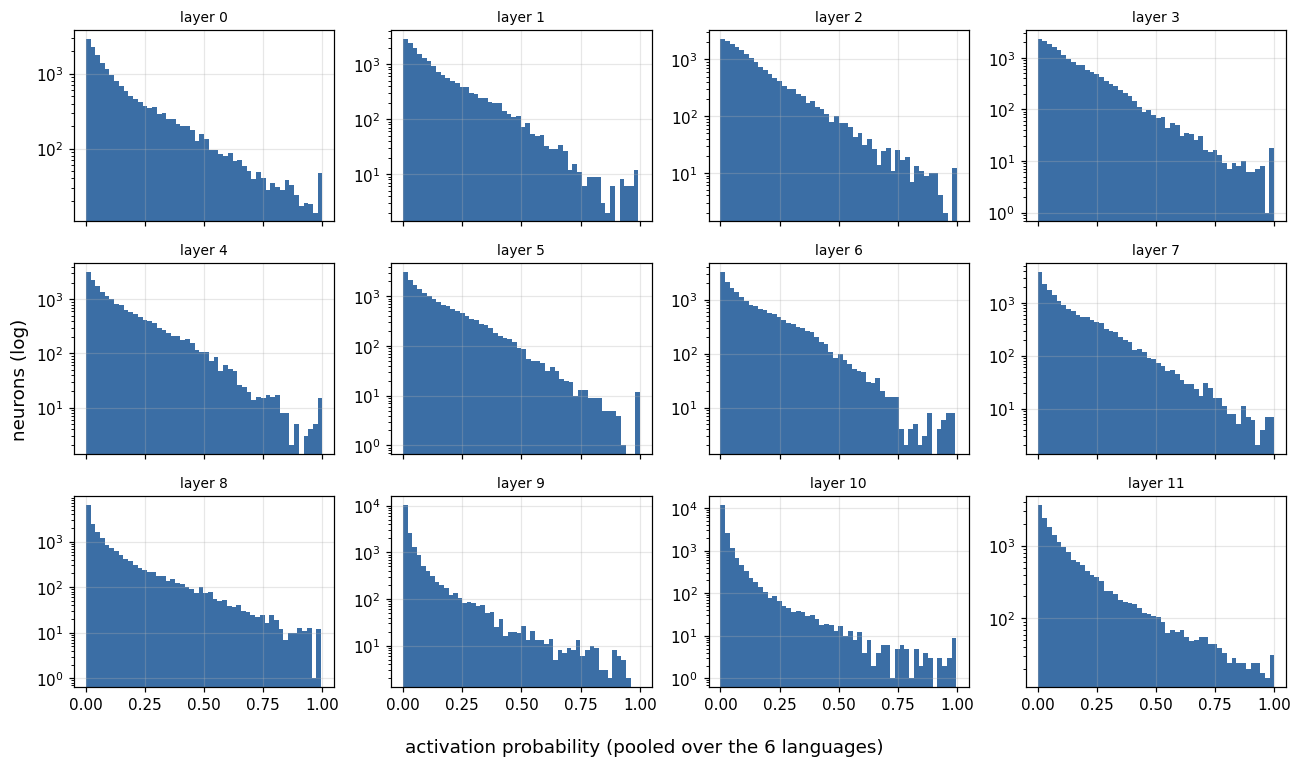

In [6]:
# Q54: sign(GELU(x)) == sign(x)
x = torch.linspace(-20, 20, 400_001)
assert ((F.gelu(x) > 0) == (x > 0)).all()
print("hidden_act =", model.config.hidden_act, "| min GELU =", F.gelu(x).min().item())

fig, axes = plt.subplots(3, 4, figsize=(12, 7), sharex=True)
for l, ax in enumerate(axes.flat):
    ax.hist(P[:, l].ravel(), bins=50, color="#3b6ea5")
    ax.set_title(f"layer {l}", fontsize=9); ax.set_yscale("log")
fig.supxlabel("activation probability (pooled over the 6 languages)"); fig.supylabel("neurons (log)")
fig.tight_layout(); fig.savefig(f"{OUT}/fig31_act_prob_hist.png")

t31 = pd.DataFrame({
    "never active (all langs)": (P.max(0) == 0).sum(1),
    "p < 0.001 (all langs)": (P.max(0) < 1e-3).sum(1),
    "p > 0.99 (all langs)": (P.min(0) > .99).sum(1),
    "median p": np.median(P, axis=(0, 2)).round(3),
}).rename_axis("layer")
t31.to_csv(f"{OUT}/t31.csv"); t31

In [7]:
# Q55: standard error sqrt(p(1-p)/n), ours vs Tang et al. (1e8 tokens)
se = (pd.DataFrame({"n": pd.concat([n_tok[LANGS], pd.Series({"Tang et al.": 10**8})])})
      .assign(**{f"SE(p={p})": lambda d, p=p: np.sqrt(p * (1 - p) / d.n) for p in (0.5, 0.05, 0.005)}))
se.to_csv(f"{OUT}/t31_se.csv"); se

,n,SE(p=0.5),SE(p=0.05),SE(p=0.005)
eng_Latn,27424,0.003019,0.001316,0.000426
fra_Latn,36573,0.002615,0.001140,0.000369
deu_Latn,34401,0.002696,0.001175,0.000380
rus_Cyrl,40190,0.002494,0.001087,0.000352
cmn_Hans,38993,0.002532,0.001104,0.000357
yor_Latn,57916,0.002078,0.000906,0.000293
Tang et al.,100000000,0.000050,0.000022,0.000007


## Task 3.2 — LAPE selection
For each set of languages: drop never-active neurons, entropy of the normalised activation probabilities
(`scipy.stats.entropy` normalises along the language axis), keep the lowest 1 %, then assign a kept neuron
to language `k` if `p_k > τ` (95th percentile of all activation probabilities).

Configurations: `main` (the six languages, as described in the assignment), `no_deu` (Q59),
`tang_code` (the order used in Tang et al.'s released code: neurons with no `p_k > τ` are discarded **before** ranking by entropy),
and `with_kaz` (bonus, seven languages, Tang et al.'s order).

In [8]:
# Q56-57
configs = {"main": (LANGS, False), "no_deu": ([c for c in LANGS if c != "deu_Latn"], False),
           "tang_code": (LANGS, True), "tang_no_deu": ([c for c in LANGS if c != "deu_Latn"], True), "with_kaz": (ALL, True)}
sel = {}
for name, (langs, prefilter) in configs.items():
    Pc = P_all[[ALL.index(c) for c in langs]]
    tau = np.quantile(Pc, .95)
    with np.errstate(invalid="ignore", divide="ignore"):
        lape = np.where(Pc.max(0) > 0, entropy(Pc, axis=0), np.inf)
    lape = np.where((Pc > tau).any(0) | (not prefilter), lape, np.inf)
    keep = np.zeros(lape.size, bool); keep[np.argsort(lape, axis=None, kind="stable")[:round(.01 * lape.size)]] = True
    keep = keep.reshape(lape.shape)
    sel[name] = dict(langs=langs, P=Pc, tau=tau, lape=lape, keep=keep, assign=(Pc > tau) & keep)

S = sel["main"]; A = S["assign"]
print(f"tau = {S['tau']:.3f} | max LAPE = ln 6 = {np.log(6):.3f} | dead neurons = {(P.max(0) == 0).sum()} | kept = {S['keep'].sum()}")
t32 = pd.DataFrame({cfg: pd.Series(sel[cfg]["assign"].sum((1, 2)), index=sel[cfg]["langs"]) for cfg in sel}).fillna(0).astype(int)
t32.loc["several languages"] = [(sel[c]["assign"].sum(0) > 1).sum() for c in sel]
t32.loc["kept but unassigned"] = [(sel[c]["keep"] & ~sel[c]["assign"].any(0)).sum() for c in sel]
t32.to_csv(f"{OUT}/t32_counts.csv"); t32

tau = 0.440 | max LAPE = ln 6 = 1.792 | dead neurons = 62 | kept = 369


,main,no_deu,tang_code,tang_no_deu,with_kaz
cmn_Hans,8,7,14,15,13
deu_Latn,13,0,48,0,56
eng_Latn,9,9,25,31,33
fra_Latn,14,15,53,63,57
kaz_Cyrl,0,0,0,0,52
rus_Cyrl,9,10,24,24,22
yor_Latn,45,41,220,246,179
several languages,0,0,15,10,38
kept but unassigned,271,287,0,0,0


main                                              tang_code                                             
      eng_Latn fra_Latn deu_Latn rus_Cyrl cmn_Hans yor_Latn  eng_Latn fra_Latn deu_Latn rus_Cyrl cmn_Hans yor_Latn
layer                                                                                                             
0            0        1        3        0        0        5         3        1       10        2        1       23
1            1        0        1        0        0        5         1        1        4        1        0       39
2            0        0        0        1        0       12         0        0        1        1        0       54
3            0        0        0        0        0        2         0        0        0        0        0       10
4            0        0        0        0        0        2         0        0        0        0        0        5
5            0        0        0        0        0        0         0        0        0        0        0        0
6            0        0        0        0        0        1         1        0        0        0        0        2
7            0        0        0        0        1        0         0        0        0        0        1        3
8            1        1        0        0        0        1         2        1        0        0        0        2
9            0        1        1        2        0        3         1        1        1        2        1        7
10           3        1        0        3        2        7         4        3        0        4        2       10
11           4       10        8        3        5        7        13       46       32       14        9       65

,eng_Latn,fra_Latn,deu_Latn,rus_Cyrl,cmn_Hans,yor_Latn
eng_Latn,9,0,0,0,0,0
fra_Latn,0,14,0,0,0,0
deu_Latn,0,0,13,0,0,0
rus_Cyrl,0,0,0,9,0,0
cmn_Hans,0,0,0,0,8,0
yor_Latn,0,0,0,0,0,45


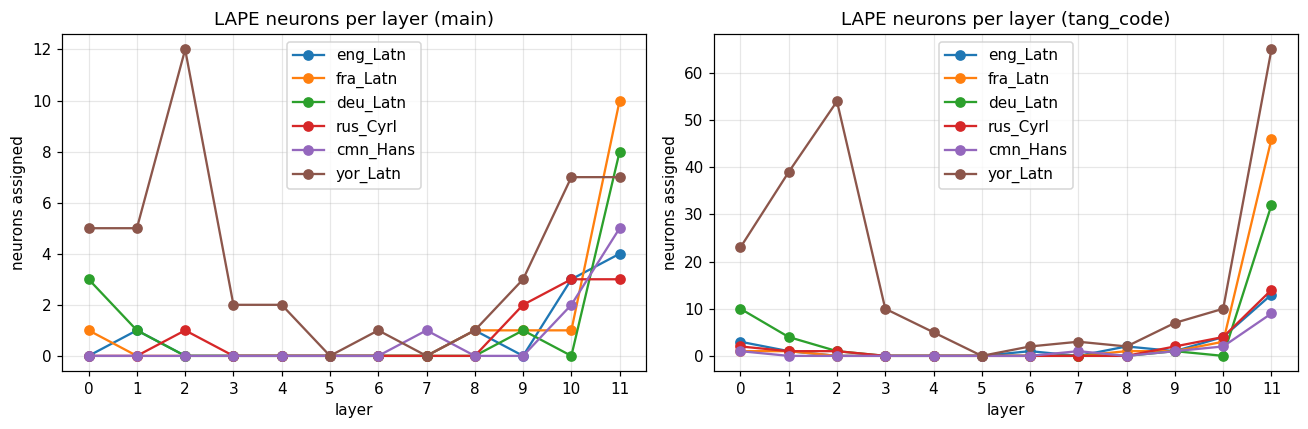

In [9]:
# Q58: selected neurons per layer
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
per_layer = {}
for ax, s_ in zip(axes, ["main", "tang_code"]):
    per_layer[s_] = pd.DataFrame(sel[s_]["assign"].sum(2).T, columns=LANGS).rename_axis("layer")
    per_layer[s_].plot(ax=ax, marker="o", title=f"LAPE neurons per layer ({s_})", ylabel="neurons assigned")
    ax.set_xticks(range(12))
fig.tight_layout(); fig.savefig(f"{OUT}/fig32_per_layer.png")
pd.concat(per_layer, names=["selection"]).to_csv(f"{OUT}/t32_per_layer.csv")
display(pd.concat(per_layer, axis=1))

# Q64: neurons shared by two languages
shared = pd.DataFrame(np.einsum("aln,bln->ab", A.astype(int), A.astype(int)), index=LANGS, columns=LANGS)
shared.to_csv(f"{OUT}/t32_shared.csv"); shared

### Q64 — Why does Yoruba get so many neurons? Tokenisation diagnostics (Part 1 in miniature)
Fertility = word pieces per word (words from mBERT's own pre-tokeniser, `word_ids`), share of continuation pieces (`##`),
of single-character pieces and of `[UNK]`, on `dev`, next to the number of neurons LAPE assigns to each language.

In [10]:
def tok_stats(sents):
    enc = tok(sents, add_special_tokens=False)
    s = pd.Series([t for ids in enc["input_ids"] for t in tok.convert_ids_to_tokens(ids)])
    n_words = sum(len({w for w in enc.word_ids(i) if w is not None}) for i in range(len(sents)))
    return {"pieces": len(s), "fertility": len(s) / n_words, "## share": s.str.startswith("##").mean(),
            "single-char share": s.str.removeprefix("##").str.len().eq(1).mean(), "[UNK] rate": (s == tok.unk_token).mean()}

tokdiag = (pd.DataFrame({c: tok_stats(dev[c].text.tolist()) for c in ALL}).T
           .assign(**{"premium vs eng": lambda d: d.pieces / d.pieces["eng_Latn"],
                      "neurons (main)": t32["main"], "neurons (tang_code)": t32["tang_code"], "neurons (with_kaz)": t32["with_kaz"]})
           .round(3))
tokdiag.to_csv(f"{OUT}/t64_tokenisation.csv"); tokdiag

,pieces,fertility,## share,single-char share,[UNK] rate,premium vs eng,neurons (main),neurons (tang_code),neurons (with_kaz)
eng_Latn,27424.0,1.130,0.115,0.163,0.001,1.000,9,25,33
fra_Latn,36573.0,1.230,0.187,0.215,0.010,1.334,14,53,57
deu_Latn,34401.0,1.396,0.283,0.160,0.002,1.254,13,48,56
rus_Cyrl,40190.0,1.741,0.426,0.260,0.003,1.466,9,24,22
cmn_Hans,38993.0,1.009,0.009,0.970,0.007,1.422,8,14,13
yor_Latn,57916.0,2.135,0.532,0.503,0.007,2.112,45,220,179
kaz_Cyrl,44826.0,2.299,0.565,0.271,0.001,1.635,0,0,52


In [11]:
# Q59 / Q65
jac = lambda a, b: (a & b).sum() / max((a | b).sum(), 1)
B = sel["no_deu"]["assign"]; T = sel["tang_code"]["assign"]
t59 = pd.DataFrame({
    "J(main, no_deu)": {c: jac(A[LANGS.index(c)], B[sel["no_deu"]["langs"].index(c)]) for c in sel["no_deu"]["langs"]},
    "J(main, tang_code)": {c: jac(A[i], T[i]) for i, c in enumerate(LANGS)},
    "J(tang_code, tang_no_deu)": {c: jac(T[i], sel["tang_no_deu"]["assign"][sel["tang_no_deu"]["langs"].index(c)])
                                  for i, c in enumerate(LANGS) if c != "deu_Latn"},
}).round(3)
t59.to_csv(f"{OUT}/t59_jaccard.csv"); t59

,"J(main, no_deu)","J(main, tang_code)","J(tang_code, tang_no_deu)"
eng_Latn,1.000,0.360,0.806
fra_Latn,0.706,0.264,0.731
rus_Cyrl,0.900,0.375,0.920
cmn_Hans,0.875,0.571,0.933
yor_Latn,0.911,0.205,0.842
deu_Latn,NaN,0.271,NaN


In [12]:
# Q62: kept neurons assigned to no language (shown as activation counts)
lost = np.argwhere(S["keep"] & ~A.any(0))
q62 = (pd.DataFrame((P[:, lost[:, 0], lost[:, 1]].T * n_tok[LANGS].values).round().astype(int), columns=LANGS)
       .assign(layer=lost[:, 0], neuron=lost[:, 1], LAPE=S["lape"][lost[:, 0], lost[:, 1]].round(3)))
print(f"{len(lost)} of {S['keep'].sum()} kept neurons are assigned to no language; their max activation count:",
      q62[LANGS].max(1).describe()[["min", "50%", "max"]].to_dict())
q62 = q62.sort_values(["LAPE", "layer"]).head(8); q62

271 of 369 kept neurons are assigned to no language; their max activation count: {'min': 1.0, '50%': 3734.0, 'max': 25382.0}


,eng_Latn,fra_Latn,deu_Latn,rus_Cyrl,cmn_Hans,yor_Latn,layer,neuron,LAPE
5,0,0,0,0,0,4,0,1842,0.0
11,0,0,0,0,0,26,1,511,0.0
20,0,0,0,0,0,1,1,2247,0.0
27,0,0,2,0,0,0,1,2811,0.0
30,0,0,0,0,0,814,2,154,0.0
31,0,0,0,0,0,1,2,315,0.0
32,0,0,0,0,0,4,2,1138,0.0
38,0,0,0,0,0,1,3,1459,0.0


## Task 3.3 — Deactivate the neurons
Same masks in every condition (300 first `devtest` sentences, seed 0). The random control draws, **layer by layer**,
as many neurons as were assigned to language `k`, among the neurons assigned to no language; three draws.
Loss increases are differences of mean cross-entropy in nats (= log of the perplexity ratio), with a paired standard error.

In [13]:
# Q66: baseline loss on the first 300 devtest sentences, masks drawn once
N_EVAL = 300
batches = {c: masked_batches(devtest[c].text[:N_EVAL].tolist(), seed=SEED) for c in ALL}
base = {c: mlm_token_losses(batches[c]) for c in ALL}
base_tab = pd.DataFrame({"masked tokens": {c: len(base[c]) for c in ALL}, "baseline loss (nats)": {c: base[c].mean() for c in ALL}}).round(3)
base_tab.to_csv(f"{OUT}/t33_baseline.csv"); base_tab

,masked tokens,baseline loss (nats)
eng_Latn,1233,2.703
fra_Latn,1711,2.079
deu_Latn,1666,2.146
rus_Cyrl,1912,1.767
cmn_Hans,1770,2.001
yor_Latn,2584,3.478
kaz_Cyrl,2072,2.175


In [14]:
# Q67-68
ABL = ["main", "tang_code"]
rng = np.random.default_rng(SEED)
sets = {}
for sname in ABL:
    As = sel[sname]["assign"]; pool = ~As.any(0)
    sets |= {(sname, "LAPE", k, 0): {l: np.flatnonzero(As[i, l]) for l in range(12)} for i, k in enumerate(LANGS)}
    sets |= {(sname, "random", k, r): {l: rng.choice(np.flatnonzero(pool[l]), As[i, l].sum(), replace=False) for l in range(12)}
             for r in range(3) for i, k in enumerate(LANGS)}
assert all(len(sets[(s_, "random", k, r)][l]) == len(sets[(s_, "LAPE", k, 0)][l]) for s_ in ABL for k in LANGS for r in range(3) for l in range(12))

if os.path.exists(f"{OUT}/t33_ablation.csv"):
    res = pd.read_csv(f"{OUT}/t33_ablation.csv")
else:
    rows = []
    for (sname, kind, k, r), ab in sets.items():
        for c in LANGS:
            d = mlm_token_losses(batches[c], ablate=ab) - base[c]
            rows.append(dict(selection=sname, kind=kind, ablated=k, draw=r, evaluated=c, delta=d.mean(),
                             se=d.std(ddof=1) / np.sqrt(len(d)), rel=d.mean() / base[c].mean(), n_neurons=sum(map(len, ab.values()))))
        print(sname, kind, k, r, "done")
    res = pd.DataFrame(rows); res.to_csv(f"{OUT}/t33_ablation.csv", index=False)

lape_res, rand_res = res.query("kind == 'LAPE'"), res.query("kind == 'random'")
M = {s_: lape_res.query("selection == @s_").pivot(index="ablated", columns="evaluated", values="delta").loc[LANGS, LANGS] for s_ in ABL}
M_se = {s_: lape_res.query("selection == @s_").pivot(index="ablated", columns="evaluated", values="se").loc[LANGS, LANGS] for s_ in ABL}
M_rel = {s_: lape_res.query("selection == @s_").pivot(index="ablated", columns="evaluated", values="rel").loc[LANGS, LANGS] for s_ in ABL}
R = {s_: rand_res.query("selection == @s_").groupby(["ablated", "evaluated"]).delta.mean().unstack().loc[LANGS, LANGS] for s_ in ABL}
R_sd = {s_: rand_res.query("selection == @s_").groupby(["ablated", "evaluated"]).delta.std().unstack().loc[LANGS, LANGS] for s_ in ABL}
pd.concat(M, names=["selection"]).round(3)

main LAPE eng_Latn 0 done
main LAPE fra_Latn 0 done
main LAPE deu_Latn 0 done
main LAPE rus_Cyrl 0 done
main LAPE cmn_Hans 0 done
main LAPE yor_Latn 0 done
main random eng_Latn 0 done
main random fra_Latn 0 done
main random deu_Latn 0 done
main random rus_Cyrl 0 done
main random cmn_Hans 0 done
main random yor_Latn 0 done
main random eng_Latn 1 done
main random fra_Latn 1 done
main random deu_Latn 1 done
main random rus_Cyrl 1 done
main random cmn_Hans 1 done
main random yor_Latn 1 done
main random eng_Latn 2 done
main random fra_Latn 2 done
main random deu_Latn 2 done
main random rus_Cyrl 2 done
main random cmn_Hans 2 done
main random yor_Latn 2 done
tang_code LAPE eng_Latn 0 done
tang_code LAPE fra_Latn 0 done
tang_code LAPE deu_Latn 0 done
tang_code LAPE rus_Cyrl 0 done
tang_code LAPE cmn_Hans 0 done
tang_code LAPE yor_Latn 0 done
tang_code random eng_Latn 0 done
tang_code random fra_Latn 0 done
tang_code random deu_Latn 0 done
tang_code random rus_Cyrl 0 done
tang_code random cmn_H

evaluated           eng_Latn  fra_Latn  deu_Latn  rus_Cyrl  cmn_Hans  yor_Latn
selection ablated                                                             
main      eng_Latn     0.015     0.001     0.001     0.001     0.001    -0.000
          fra_Latn     0.004     0.134     0.002     0.001     0.001     0.001
          deu_Latn    -0.000     0.002     0.039     0.001     0.001    -0.001
          rus_Cyrl     0.003     0.003     0.002     0.079     0.000     0.001
          cmn_Hans     0.000     0.000    -0.001     0.001     0.082     0.003
          yor_Latn     0.003     0.011     0.003     0.003    -0.013     0.150
tang_code eng_Latn     0.031     0.003     0.007     0.003     0.003     0.002
          fra_Latn     0.007     0.158     0.011     0.003     0.005     0.012
          deu_Latn    -0.001     0.007     0.055     0.003     0.002     0.002
          rus_Cyrl     0.008     0.003     0.000     0.106     0.002     0.002
          cmn_Hans     0.001     0.001    -0.001     0.011     0.091     0.007
          yor_Latn     0.009     0.022     0.009     0.001    -0.002     0.368

n neurons  diag (LAPE)  off-diag mean (LAPE)  diag (random)  off-diag mean (random)
selection                                                                                              
main      eng_Latn          9        0.015                 0.001          0.001                   0.001
          fra_Latn         14        0.134                 0.002         -0.001                   0.001
          deu_Latn         13        0.039                 0.000          0.001                   0.001
          rus_Cyrl          9        0.079                 0.002          0.001                   0.001
          cmn_Hans          8        0.082                 0.001          0.001                   0.001
          yor_Latn         45        0.150                 0.002          0.002                   0.003
tang_code eng_Latn         25        0.031                 0.004          0.001                   0.003
          fra_Latn         53        0.158                 0.008          0.006                   0.005
          deu_Latn         48        0.055                 0.003          0.010                  -0.007
          rus_Cyrl         24        0.106                 0.003          0.004                   0.002
          cmn_Hans         14        0.091                 0.004          0.000                   0.001
          yor_Latn        220        0.368                 0.008         -0.016                   0.008

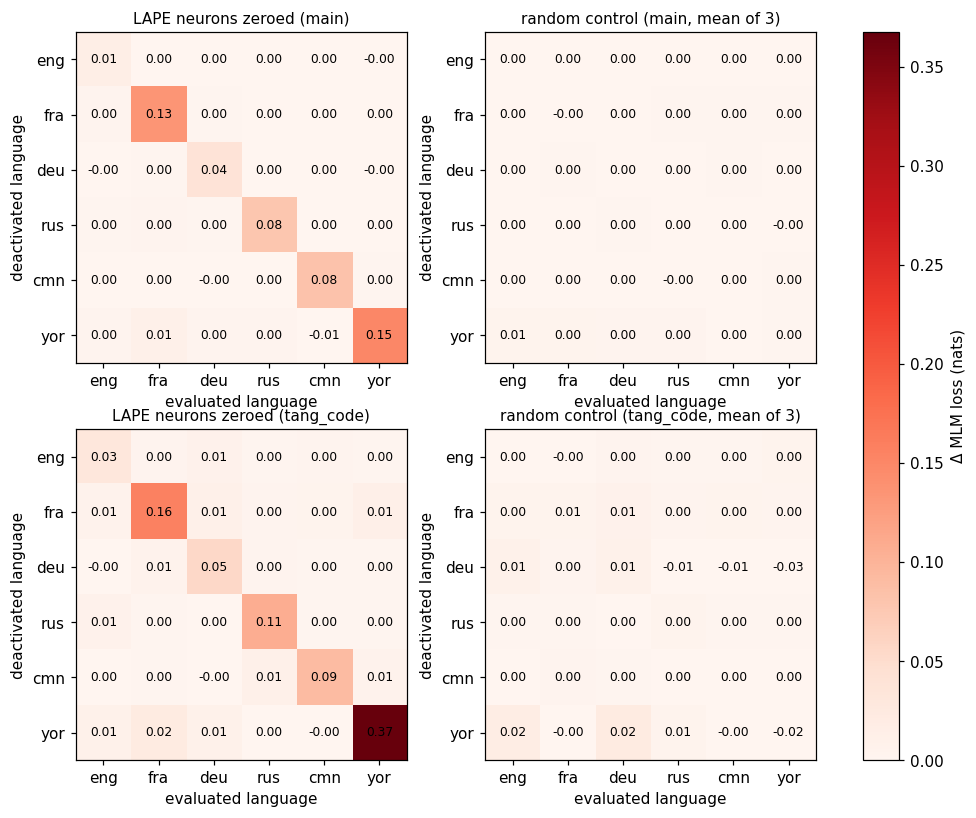

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8.6))
vmax = max(max(t.values.max() for t in M.values()), max(t.values.max() for t in R.values()), 1e-3)
for row, s_ in zip(axes, ABL):
    for ax, (title, t) in zip(row, {f"LAPE neurons zeroed ({s_})": M[s_], f"random control ({s_}, mean of 3)": R[s_]}.items()):
        im = ax.imshow(t.values, cmap="Reds", vmin=0, vmax=vmax)
        ax.set_xticks(range(6), [c[:3] for c in LANGS]); ax.set_yticks(range(6), [c[:3] for c in LANGS])
        ax.set_xlabel("evaluated language"); ax.set_ylabel("deactivated language"); ax.set_title(title, fontsize=10); ax.grid(False)
        [ax.text(j, i, f"{t.values[i, j]:.2f}", ha="center", va="center", fontsize=8) for i in range(6) for j in range(6)]
fig.colorbar(im, ax=axes, label="Δ MLM loss (nats)"); fig.savefig(f"{OUT}/fig33_ablation.png", bbox_inches="tight")

# diagonal vs mean off-diagonal
spec = pd.concat({s_: pd.DataFrame({
    "n neurons": lape_res.query("selection == @s_").groupby("ablated").n_neurons.first().loc[LANGS],
    "diag (LAPE)": np.diag(M[s_]), "off-diag mean (LAPE)": (M[s_].values.sum(1) - np.diag(M[s_])) / 5,
    "diag (random)": np.diag(R[s_]), "off-diag mean (random)": (R[s_].values.sum(1) - np.diag(R[s_])) / 5,
}, index=LANGS) for s_ in ABL}, names=["selection"]).round(3)
spec.to_csv(f"{OUT}/t33_specificity.csv"); spec

### Q67–72 — Are the effects significant? Every number with its reference point
`Δ ± SE` (paired SE over masked tokens) for LAPE, `mean ± SD` over the three draws for the random control,
`z = Δ / SE`, and the diagonal effect as a perplexity ratio `exp(Δ) − 1` and per deactivated neuron.

In [16]:
fmt = lambda m, e: m.round(3).astype(str) + " ± " + e.round(3).astype(str)
display(pd.concat({s_: fmt(M[s_], M_se[s_]) for s_ in ABL}, names=["LAPE, selection"]))
display(pd.concat({s_: fmt(R[s_], R_sd[s_]) for s_ in ABL}, names=["random, selection"]))
Z = pd.concat({s_: (M[s_] / M_se[s_]).round(1) for s_ in ABL}, names=["z, selection"]); display(Z)
n_abl = lape_res.groupby(["selection", "ablated"]).n_neurons.first()
diag_tab = pd.concat({s_: pd.DataFrame({
    "n neurons": n_abl[s_].loc[LANGS], "Δ diag": np.diag(M[s_]), "z diag": np.diag(M[s_] / M_se[s_]),
    "ppl +%": 100 * (np.exp(np.diag(M[s_])) - 1), "Δ per neuron (×1000)": 1000 * np.diag(M[s_]) / n_abl[s_].loc[LANGS].values,
    "diag is max of row": [M[s_].loc[k].idxmax() == k for k in LANGS], "diag is max of column": [M[s_][k].idxmax() == k for k in LANGS],
    "|off-diag| max": [M[s_].loc[k].drop(k).abs().max() for k in LANGS], "z of that": [(M[s_] / M_se[s_]).loc[k, M[s_].loc[k].drop(k).abs().idxmax()] for k in LANGS],
}, index=LANGS) for s_ in ABL}, names=["selection"]).round(3)
diag_tab.to_csv(f"{OUT}/t33_diag.csv"); diag_tab

evaluated                       eng_Latn       fra_Latn        deu_Latn       rus_Cyrl        cmn_Hans        yor_Latn
LAPE, selection ablated                                                                                               
main            eng_Latn   0.015 ± 0.007  0.001 ± 0.001   0.001 ± 0.001  0.001 ± 0.001   0.001 ± 0.001    -0.0 ± 0.001
                fra_Latn   0.004 ± 0.001   0.134 ± 0.01   0.002 ± 0.001  0.001 ± 0.001   0.001 ± 0.001   0.001 ± 0.001
                deu_Latn    -0.0 ± 0.001  0.002 ± 0.001   0.039 ± 0.007  0.001 ± 0.001   0.001 ± 0.001  -0.001 ± 0.001
                rus_Cyrl   0.003 ± 0.001  0.003 ± 0.001   0.002 ± 0.001  0.079 ± 0.008       0.0 ± 0.0     0.001 ± 0.0
                cmn_Hans     0.0 ± 0.001    0.0 ± 0.001  -0.001 ± 0.001  0.001 ± 0.001    0.082 ± 0.01   0.003 ± 0.001
                yor_Latn   0.003 ± 0.002  0.011 ± 0.003   0.003 ± 0.002  0.003 ± 0.001  -0.013 ± 0.004    0.15 ± 0.012
tang_code       eng_Latn   0.031 ± 0.011  0.003 ± 0.002   0.007 ± 0.002  0.003 ± 0.001   0.003 ± 0.001   0.002 ± 0.002
                fra_Latn   0.007 ± 0.002  0.158 ± 0.012   0.011 ± 0.002  0.003 ± 0.002   0.005 ± 0.001   0.012 ± 0.005
                deu_Latn  -0.001 ± 0.002  0.007 ± 0.002   0.055 ± 0.009  0.003 ± 0.002   0.002 ± 0.001   0.002 ± 0.002
                rus_Cyrl   0.008 ± 0.001  0.003 ± 0.001     0.0 ± 0.001  0.106 ± 0.009   0.002 ± 0.002   0.002 ± 0.001
                cmn_Hans   0.001 ± 0.001  0.001 ± 0.001  -0.001 ± 0.001  0.011 ± 0.002    0.091 ± 0.01   0.007 ± 0.001
                yor_Latn   0.009 ± 0.003  0.022 ± 0.004   0.009 ± 0.003  0.001 ± 0.003  -0.002 ± 0.005   0.368 ± 0.019

evaluated                        eng_Latn        fra_Latn       deu_Latn        rus_Cyrl        cmn_Hans        yor_Latn
random, selection ablated                                                                                               
main              eng_Latn  0.001 ± 0.001       0.0 ± 0.0  0.001 ± 0.001   0.001 ± 0.001     0.001 ± 0.0     0.0 ± 0.002
                  fra_Latn  0.001 ± 0.001  -0.001 ± 0.001    0.0 ± 0.002   0.002 ± 0.001   0.002 ± 0.001   0.002 ± 0.002
                  deu_Latn  0.001 ± 0.003   0.002 ± 0.001  0.001 ± 0.001   0.001 ± 0.001   0.002 ± 0.003   0.001 ± 0.001
                  rus_Cyrl  0.001 ± 0.001   0.001 ± 0.001  0.002 ± 0.002   0.001 ± 0.001     0.0 ± 0.001  -0.001 ± 0.001
                  cmn_Hans  0.001 ± 0.001   0.001 ± 0.001      0.0 ± 0.0      -0.0 ± 0.0     0.001 ± 0.0   0.002 ± 0.001
                  yor_Latn  0.005 ± 0.004   0.005 ± 0.006  0.003 ± 0.004   0.003 ± 0.003     0.0 ± 0.003   0.002 ± 0.005
tang_code         eng_Latn  0.001 ± 0.002    -0.0 ± 0.003  0.003 ± 0.003   0.002 ± 0.001   0.003 ± 0.002   0.005 ± 0.003
                  fra_Latn  0.005 ± 0.006   0.006 ± 0.006  0.008 ± 0.005   0.004 ± 0.005   0.005 ± 0.002   0.004 ± 0.005
                  deu_Latn  0.009 ± 0.006   0.003 ± 0.017   0.01 ± 0.006  -0.008 ± 0.018   -0.01 ± 0.024  -0.028 ± 0.073
                  rus_Cyrl  0.002 ± 0.002   0.002 ± 0.001  0.001 ± 0.001     0.004 ± 0.0   0.003 ± 0.003   0.002 ± 0.005
                  cmn_Hans    0.0 ± 0.004   0.003 ± 0.005  0.001 ± 0.001   0.001 ± 0.002     0.0 ± 0.002     0.0 ± 0.002
                  yor_Latn  0.017 ± 0.004  -0.002 ± 0.019  0.022 ± 0.003   0.005 ± 0.021  -0.003 ± 0.022  -0.016 ± 0.063

evaluated              eng_Latn  fra_Latn  deu_Latn  rus_Cyrl  cmn_Hans  yor_Latn
z, selection ablated                                                             
main         eng_Latn       2.0       1.8       1.3       1.3       1.1      -0.3
             fra_Latn       4.2      13.0       2.4       1.3       0.9       0.5
             deu_Latn      -0.6       2.6       5.3       1.0       1.0      -1.6
             rus_Cyrl       3.4       5.1       2.0      10.1       0.9       1.5
             cmn_Hans       0.3       0.2      -1.0       1.2       8.2       4.7
             yor_Latn       1.6       4.3       2.1       2.7      -2.9      12.7
tang_code    eng_Latn       2.9       1.6       4.6       2.2       2.4       0.7
             fra_Latn       3.6      13.5       4.7       1.8       3.5       2.3
             deu_Latn      -0.8       3.9       6.2       1.6       1.3       1.3
             rus_Cyrl       5.6       2.4       0.1      12.4       0.9       1.4
             cmn_Hans       1.0       1.5      -1.3       4.8       9.1       6.9
             yor_Latn       2.7       5.3       2.7       0.2      -0.5      19.4

n neurons  Δ diag  z diag     ppl +%  Δ per neuron (×1000)  diag is max of row  diag is max of column  |off-diag| max  z of that
selection                                                                                                                                           
main      eng_Latn          9   0.015   2.031   1.491000                 1.644                True                   True           0.001      1.770
          fra_Latn         14   0.134  12.952  14.310000                 9.553                True                   True           0.004      4.183
          deu_Latn         13   0.039   5.298   3.944000                 2.976                True                   True           0.002      2.601
          rus_Cyrl          9   0.079  10.140   8.173000                 8.729                True                   True           0.003      5.146
          cmn_Hans          8   0.082   8.231   8.560000                10.266                True                   True           0.003      4.703
          yor_Latn         45   0.150  12.690  16.238001                 3.344                True                   True           0.013     -2.934
tang_code eng_Latn         25   0.031   2.861   3.135000                 1.235                True                   True           0.007      4.601
          fra_Latn         53   0.158  13.543  17.065001                 2.973                True                   True           0.012      2.269
          deu_Latn         48   0.055   6.230   5.612000                 1.137                True                   True           0.007      3.870
          rus_Cyrl         24   0.106  12.368  11.225000                 4.433                True                   True           0.008      5.639
          cmn_Hans         14   0.091   9.146   9.572000                 6.530                True                   True           0.011      4.848
          yor_Latn        220   0.368  19.413  44.426998                 1.671                True                   True           0.022      5.336

### A stricter control: neurons that are just as *active*, but not language-specific
The control of Q68 compares LAPE neurons with neurons of the same layers, but LAPE neurons are, by construction, very active on their
language (`p_k > τ`), whereas a typical neuron is active on ≈ 9 % of tokens. Part of the diagonal could therefore be
"zeroing frequently-firing neurons hurts", and the near-zero off-diagonal is partly built in, since LAPE neurons are almost silent on the other languages.
Here, for each language `k` and layer, we draw the same number of neurons among the neurons **not assigned to any language but with `p_k > τ`**
(active on `k`, but with a high entropy, i.e. also active elsewhere). Three draws.

In [17]:
if os.path.exists(f"{OUT}/t33_active_control.csv"):
    act = pd.read_csv(f"{OUT}/t33_active_control.csv")
else:
    rng = np.random.default_rng(SEED + 1); rows = []
    for s_ in ABL:
        As = sel[s_]["assign"]
        for i, k in enumerate(LANGS):
            for r in range(3):
                ab = {}
                for l in range(12):
                    cand = np.flatnonzero(~As.any(0)[l] & (P[i, l] > S["tau"]))
                    ab[l] = rng.choice(cand, min(As[i, l].sum(), len(cand)), replace=False)
                short = int(As[i].sum() - sum(map(len, ab.values())))
                for c in LANGS:
                    d = mlm_token_losses(batches[c], ablate=ab) - base[c]
                    rows.append(dict(selection=s_, ablated=k, draw=r, evaluated=c, delta=d.mean(), n_neurons=sum(map(len, ab.values())), shortfall=short))
            print(s_, k, "done")
    act = pd.DataFrame(rows); act.to_csv(f"{OUT}/t33_active_control.csv", index=False)

C = {s_: act.query("selection == @s_").groupby(["ablated", "evaluated"]).delta.mean().unstack().loc[LANGS, LANGS] for s_ in ABL}
C_sd = {s_: act.query("selection == @s_").groupby(["ablated", "evaluated"]).delta.std().unstack().loc[LANGS, LANGS] for s_ in ABL}
display(pd.concat({s_: fmt(C[s_], C_sd[s_]) for s_ in ABL}, names=["active control, selection"]))
print("neurons missing because the pool was too small:", act.groupby(["selection", "ablated"]).shortfall.first().to_dict())
cmp_tab = pd.concat({s_: pd.DataFrame({
    "diag LAPE": np.diag(M[s_]), "diag active ctrl": np.diag(C[s_]), "diag random": np.diag(R[s_]),
    "off-diag mean LAPE": (M[s_].values.sum(1) - np.diag(M[s_])) / 5, "off-diag mean active ctrl": (C[s_].values.sum(1) - np.diag(C[s_])) / 5,
    "diag − off LAPE": np.diag(M[s_]) - (M[s_].values.sum(1) - np.diag(M[s_])) / 5,
    "diag − off active ctrl": np.diag(C[s_]) - (C[s_].values.sum(1) - np.diag(C[s_])) / 5,
}, index=LANGS) for s_ in ABL}, names=["selection"]).round(3)
cmp_tab.to_csv(f"{OUT}/t33_active_compare.csv"); cmp_tab

main eng_Latn done
main fra_Latn done
main deu_Latn done
main rus_Cyrl done
main cmn_Hans done
main yor_Latn done
tang_code eng_Latn done
tang_code fra_Latn done
tang_code deu_Latn done
tang_code rus_Cyrl done
tang_code cmn_Hans done
tang_code yor_Latn done


evaluated                                 eng_Latn        fra_Latn       deu_Latn       rus_Cyrl        cmn_Hans        yor_Latn
active control, selection ablated                                                                                               
main                      eng_Latn   0.001 ± 0.002   0.003 ± 0.002  0.004 ± 0.002  0.003 ± 0.002     0.002 ± 0.0   0.003 ± 0.003
                          fra_Latn   0.003 ± 0.004    0.009 ± 0.01  0.003 ± 0.001  0.001 ± 0.002   0.002 ± 0.001   0.006 ± 0.007
                          deu_Latn   0.021 ± 0.019   0.008 ± 0.005  0.031 ± 0.024  0.016 ± 0.013    0.013 ± 0.01  -0.013 ± 0.014
                          rus_Cyrl   0.002 ± 0.003  -0.003 ± 0.003  0.002 ± 0.003  0.007 ± 0.007  -0.003 ± 0.002   0.007 ± 0.014
                          cmn_Hans    0.004 ± 0.01  -0.002 ± 0.005  0.003 ± 0.004  0.005 ± 0.012   0.005 ± 0.009   0.002 ± 0.014
                          yor_Latn  -0.006 ± 0.006    -0.0 ± 0.004  0.001 ± 0.004  0.003 ± 0.002    0.002 ± 0.01   0.026 ± 0.015
tang_code                 eng_Latn   0.004 ± 0.004  -0.002 ± 0.009  0.003 ± 0.008  0.001 ± 0.001   0.002 ± 0.003     0.0 ± 0.006
                          fra_Latn     0.0 ± 0.004   0.008 ± 0.007  0.008 ± 0.003  0.004 ± 0.004   0.007 ± 0.014   0.005 ± 0.007
                          deu_Latn   0.005 ± 0.006   0.007 ± 0.008  0.014 ± 0.002  0.004 ± 0.004   0.002 ± 0.003  -0.001 ± 0.006
                          rus_Cyrl   0.002 ± 0.006   0.002 ± 0.006  0.005 ± 0.003  0.003 ± 0.003   0.003 ± 0.006   0.011 ± 0.014
                          cmn_Hans    0.01 ± 0.013   0.002 ± 0.001  0.005 ± 0.004  0.005 ± 0.003   0.045 ± 0.066    0.01 ± 0.012
                          yor_Latn   0.013 ± 0.016   0.016 ± 0.007  0.025 ± 0.017  0.016 ± 0.004   0.017 ± 0.021   0.047 ± 0.025

neurons missing because the pool was too small: {('main', 'cmn_Hans'): 0, ('main', 'deu_Latn'): 0, ('main', 'eng_Latn'): 0, ('main', 'fra_Latn'): 0, ('main', 'rus_Cyrl'): 0, ('main', 'yor_Latn'): 0, ('tang_code', 'cmn_Hans'): 0, ('tang_code', 'deu_Latn'): 0, ('tang_code', 'eng_Latn'): 0, ('tang_code', 'fra_Latn'): 0, ('tang_code', 'rus_Cyrl'): 0, ('tang_code', 'yor_Latn'): 0}


diag LAPE  diag active ctrl  diag random  off-diag mean LAPE  off-diag mean active ctrl  diag − off LAPE  diag − off active ctrl
selection                                                                                                                                           
main      eng_Latn      0.015             0.001        0.001               0.001                      0.003            0.014                  -0.002
          fra_Latn      0.134             0.009       -0.001               0.002                      0.003            0.132                   0.006
          deu_Latn      0.039             0.031        0.001               0.000                      0.009            0.038                   0.022
          rus_Cyrl      0.079             0.007        0.001               0.002                      0.001            0.077                   0.006
          cmn_Hans      0.082             0.005        0.001               0.001                      0.003            0.081                   0.002
          yor_Latn      0.150             0.026        0.002               0.002                      0.000            0.149                   0.026
tang_code eng_Latn      0.031             0.004        0.001               0.004                      0.001            0.027                   0.003
          fra_Latn      0.158             0.008        0.006               0.008                      0.005            0.150                   0.003
          deu_Latn      0.055             0.014        0.010               0.003                      0.003            0.052                   0.011
          rus_Cyrl      0.106             0.003        0.004               0.003                      0.005            0.104                  -0.001
          cmn_Hans      0.091             0.045        0.000               0.004                      0.006            0.088                   0.039
          yor_Latn      0.368             0.047       -0.016               0.008                      0.017            0.360                   0.030

## Bonus — and Kazakh? (*Қазақша да бар!*)
`kaz_Cyrl` is one of mBERT's 104 languages and shares the Cyrillic script with Russian (plus 9 extra letters: ә ғ қ ң ө ұ ү һ і).
Selection over seven languages (Tang et al.'s order), then zero the Kazakh and the Russian neurons and evaluate on the seven languages.

In [18]:
K = sel["with_kaz"]; AK = K["assign"]
shared_k = pd.DataFrame(np.einsum("aln,bln->ab", AK.astype(int), AK.astype(int)), index=ALL, columns=ALL)
shared_k.to_csv(f"{OUT}/bonus_shared.csv")

if os.path.exists(f"{OUT}/bonus_ablation.csv"):
    bonus = pd.read_csv(f"{OUT}/bonus_ablation.csv", index_col=0)
else:
    bonus = pd.DataFrame({k: {c: (mlm_token_losses(batches[c], {l: np.flatnonzero(AK[ALL.index(k), l]) for l in range(12)}) - base[c]).mean()
                              for c in ALL} for k in ["kaz_Cyrl", "rus_Cyrl"]}).T
    bonus.to_csv(f"{OUT}/bonus_ablation.csv")
display(shared_k.loc[["rus_Cyrl", "kaz_Cyrl"]]); bonus.round(3)

,eng_Latn,fra_Latn,deu_Latn,rus_Cyrl,cmn_Hans,yor_Latn,kaz_Cyrl
rus_Cyrl,0,1,2,22,2,0,8
kaz_Cyrl,0,1,0,8,4,14,52


,eng_Latn,fra_Latn,deu_Latn,rus_Cyrl,cmn_Hans,yor_Latn,kaz_Cyrl
kaz_Cyrl,0.006,0.006,0.003,0.024,0.030,0.04,0.068
rus_Cyrl,0.009,0.003,-0.000,0.104,0.001,-0.00,0.026


### Q73 — What do the selected neurons actually respond to?
For a few neurons (the three most active assigned neurons of each language in `tang_code`, plus the neurons that the seven-language
selection assigns to *both* Kazakh and Yoruba, or Kazakh and Russian), we record the activation on every `dev` token of the seven languages
and list the tokens with the largest activations, the languages of the top-200 activations, and the share of continuation / single-character pieces among them.

In [19]:
TT = sel["tang_code"]
picks = [(l, j, f"{k[:3]} #{n + 1}") for i, k in enumerate(LANGS)
         for n, (l, j) in enumerate(sorted(zip(*np.nonzero(TT["assign"][i])), key=lambda lj: -P[i][lj])[:3])]
for a, b in [("kaz_Cyrl", "yor_Latn"), ("kaz_Cyrl", "rus_Cyrl")]:
    both = AK[ALL.index(a)] & AK[ALL.index(b)]
    picks += [(l, j, f"{a[:3]}+{b[:3]}") for l, j in list(zip(*np.nonzero(both)))[:4]]
picks = pd.DataFrame(picks, columns=["layer", "neuron", "label"]).groupby(["layer", "neuron"]).label.agg(", ".join).reset_index()

if os.path.exists(f"{OUT}/t73_top_tokens.csv"):
    top_tab = pd.read_csv(f"{OUT}/t73_top_tokens.csv")
else:
    by_layer = picks.groupby("layer").neuron.apply(list).to_dict()
    store, state, toks, langs = {l: [] for l in by_layer}, {}, [], []
    rec = lambda l: (lambda m, i, o: store[l].append(o[..., by_layer[l]][state["keep"]].float().cpu()))
    handles = [model.bert.encoder.layer[l].intermediate.register_forward_hook(rec(l)) for l in by_layer]
    for c in ALL:
        for i in range(0, len(dev[c]), 32):
            enc, keep = encode(dev[c].text[i:i + 32].tolist())
            state["keep"] = keep.to(DEV); model.bert(**enc.to(DEV))
            toks += tok.convert_ids_to_tokens(enc["input_ids"].cpu()[keep].tolist()); langs += [c[:3]] * int(keep.sum())
    [h.remove() for h in handles]
    acts = {l: torch.cat(store[l]).numpy() for l in store}
    tokens, lang_s = pd.Series(toks), pd.Series(langs)
    rows = []
    for _, r in picks.iterrows():
        top = pd.DataFrame({"tok": tokens, "lang": lang_s, "a": acts[r.layer][:, by_layer[r.layer].index(r.neuron)]}).nlargest(200, "a")
        rows.append({"label": r.label, "layer": r.layer, "neuron": r.neuron,
                     "top tokens": " ".join(top.drop_duplicates("tok").tok.head(12)),
                     "langs (top-200)": ", ".join(f"{k}:{v}" for k, v in top.lang.value_counts().head(3).items()),
                     "## share": top.tok.str.startswith("##").mean().round(2),
                     "1-char share": top.tok.str.removeprefix("##").str.len().eq(1).mean().round(2)})
    top_tab = pd.DataFrame(rows); top_tab.to_csv(f"{OUT}/t73_top_tokens.csv", index=False)
top_tab

,label,layer,neuron,top tokens,langs (top-200),## share,1-char share
0,kaz+yor,0,240,te le d по din to r in i l at t,"yor:195, kaz:5",0.01,0.66
1,kaz+yor,0,473,##нал ##ман ##ри ##нем ##ни ##нама ##зы ##нала ##лу е ##би ##á,"kaz:167, yor:33",0.84,0.32
2,kaz+yor,0,690,##iri ##un ##уда ##ír ##ir ##у ##с ##уд ##n ##wa ##mu -,"yor:138, kaz:62",1.00,0.18
3,kaz+yor,0,852,##пер пер ##ye ##әсе ##гер ##өр ##елес ##нета ##нем ì ##ә ##bí,"kaz:138, yor:62",0.72,0.31
4,yor #1,8,2868,##n i yi bi ##a ri na ni kan in ##re to,yor:200,0.28,0.30
5,kaz+rus,9,973,в ##е на ##м ##ом ##и ##му ##ю ##ми ##у ##ы ##ском,rus:200,0.66,0.66
6,yor #2,10,1869,ti ni à n tí - kan ní náà ó sí i,yor:200,0.09,0.44
7,eng #1,11,72,"##closed s ##s en "" blow ##ment the States E ##ro or",eng:200,0.24,0.14
8,rus #3,11,115,из но от за для ##рь качестве ##м Б ##ес с ##й,"rus:196, kaz:3, deu:1",0.20,0.34
9,"rus #1, cmn #3",11,244,##ың от В ##ие б С из и ##ного М 的 Б,"rus:120, kaz:62, cmn:17",0.36,0.55


## Task 3.4 — Neurons and subspaces (optional)
At `hidden_states[l+1]`, `Q` = orthonormal basis of the span of the six **centred** language means (rank 5).
For a neuron, $r_j = \|Q^\top w_j\|^2 / \|w_j\|^2$, where $w_j$ is column $j$ of `output.dense.weight`.
We also compute $r_j$ for $\tilde w_j = \gamma \odot (w_j - \bar w_j)$, a first-order account of the LayerNorm that follows the residual addition (Q76).

In [20]:
if os.path.exists(f"{OUT}/lang_means.npy"):
    means = np.load(f"{OUT}/lang_means.npy")
else:
    means = np.stack([sentence_reps(dev[c].text.tolist()).mean(1) for c in LANGS])   # (6, 13, 768)
    np.save(f"{OUT}/lang_means.npy", means)

W = torch.stack([l.output.dense.weight for l in model.bert.encoder.layer]).cpu().numpy()      # (12, 768, 3072)
G = torch.stack([l.output.LayerNorm.weight for l in model.bert.encoder.layer]).cpu().numpy()  # (12, 768)
Wt = G[:, :, None] * (W - W.mean(1, keepdims=True))
Mc = means[:, 1:] - means[:, 1:].mean(0)                                                      # (6, 12, 768), centred
Q = np.linalg.svd(Mc.transpose(1, 2, 0), full_matrices=False)[0][:, :, :len(LANGS) - 1]      # (12, 768, 5)
r_raw = (np.einsum("ldk,ldn->lkn", Q, W) ** 2).sum(1) / (W ** 2).sum(1)                      # (12, 3072)
r_ln = (np.einsum("ldk,ldn->lkn", Q, Wt) ** 2).sum(1) / (Wt ** 2).sum(1)

# Q74: random directions, E[r] = k/d
u = np.random.default_rng(SEED).standard_normal((768, 20_000))
print("k/d =", 5 / 768, "| random directions:", ((np.einsum("dk,dn->kn", Q[6], u) ** 2).sum(0) / (u ** 2).sum(0)).mean())

rand_mask = {s_: np.zeros_like(A[0]) for s_ in ABL}
for (s_, kind, k, r), ab in sets.items():
    for l, idx in ab.items():
        rand_mask[s_][l, idx] |= kind == "random"
t34 = pd.concat({s_: pd.DataFrame({
    **{f"LAPE {c[:3]}": (r_raw[As[i]].mean(), r_ln[As[i]].mean()) for i, c in enumerate(LANGS) if As[i].any()},
    "LAPE (all)": (r_raw[As.any(0)].mean(), r_ln[As.any(0)].mean()),
    "random (same layers)": (r_raw[rand_mask[s_]].mean(), r_ln[rand_mask[s_]].mean()),
    "all neurons": (r_raw.mean(), r_ln.mean()), "k/d": (5 / 768, 5 / 768),
}, index=["r (raw w)", "r (LN-corrected w)"]).T for s_, As in ((s_, sel[s_]["assign"]) for s_ in ABL)}, names=["selection"]).round(4)
t34.to_csv(f"{OUT}/t34.csv"); display(t34)

# per layer (tang_code)
At = sel["tang_code"]["assign"].any(0)
t34_layer = pd.DataFrame({"n LAPE": At.sum(1), "r LAPE": [r_raw[l][At[l]].mean() if At[l].any() else np.nan for l in range(12)],
                          "r all neurons": r_raw.mean(1), "k/d": 5 / 768}).rename_axis("layer").round(4)
t34_layer.to_csv(f"{OUT}/t34_layer.csv"); t34_layer

k/d = 0.006510416666666667 | random directions: 0.0065214686102097776


r (raw w)  r (LN-corrected w)
selection                                                    
main      LAPE eng                 0.1437              0.1443
          LAPE fra                 0.1195              0.1204
          LAPE deu                 0.0810              0.0812
          LAPE rus                 0.1163              0.1174
          LAPE cmn                 0.1182              0.1230
          LAPE yor                 0.0319              0.0324
          LAPE (all)               0.0760              0.0769
          random (same layers)     0.0059              0.0058
          all neurons              0.0062              0.0060
          k/d                      0.0065              0.0065
tang_code LAPE eng                 0.0907              0.0913
          LAPE fra                 0.0391              0.0400
          LAPE deu                 0.0293              0.0293
          LAPE rus                 0.0728              0.0732
          LAPE cmn                 0.0801              0.0827
          LAPE yor                 0.0130              0.0129
          LAPE (all)               0.0303              0.0305
          random (same layers)     0.0075              0.0073
          all neurons              0.0062              0.0060
          k/d                      0.0065              0.0065

,n LAPE,r LAPE,r all neurons,k/d
layer,,,,
0,40,0.0408,0.0108,0.0065
1,45,0.0134,0.0066,0.0065
2,56,0.0107,0.0061,0.0065
3,10,0.0243,0.0053,0.0065
4,5,0.0218,0.0049,0.0065
5,0,NaN,0.0045,0.0065
6,3,0.1068,0.0048,0.0065
7,4,0.0567,0.0052,0.0065
8,5,0.1471,0.0067,0.0065
